# Assignment: 0-1 Knapsack (DP and Branch & Bound)

In [1]:
from collections import deque


def dp_knapsack(weights, profits, capacity):
    n = len(weights)
    dp = [[0] * (capacity + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        for w in range(capacity + 1):
            dp[i][w] = dp[i - 1][w]
            if weights[i - 1] <= w:
                dp[i][w] = max(
                    dp[i][w],
                    profits[i - 1] + dp[i - 1][w - weights[i - 1]]
                )

    return dp[n][capacity]


def bb_knapsack(weights, profits, capacity):
    items = sorted(
        zip(weights, profits),
        key=lambda item: item[1] / item[0],
        reverse=True
    )

    n = len(items)
    best = 0
    q = deque([(0, 0, 0)])

    def bound(i, p, w):
        total = p
        while i < n and w + items[i][0] <= capacity:
            w += items[i][0]
            total += items[i][1]
            i += 1
        if i < n:
            total += (capacity - w) * items[i][1] / items[i][0]
        return total

    while q:
        i, p, w = q.popleft()
        best = max(best, p)

        if i == n:
            continue

        wt, pr = items[i]

        if w + wt <= capacity:
            if bound(i + 1, p + pr, w + wt) > best:
                q.append((i + 1, p + pr, w + wt))

        if bound(i + 1, p, w) > best:
            q.append((i + 1, p, w))

    return best


weights = [10, 20, 30]
profits = [60, 100, 120]
capacity = 50

print("Weights:", weights)
print("Profits:", profits)
print("Capacity:", capacity)
print("Maximum Profit (DP):", dp_knapsack(weights, profits, capacity))
print("Maximum Profit (B&B):", bb_knapsack(weights, profits, capacity))

print("\nTime and Space Complexity")
print("DP  : Time O(nW), Space O(nW)")
print("B&B : Time O(2^n) worst case, Space O(n)")

Weights: [10, 20, 30]
Profits: [60, 100, 120]
Capacity: 50
Maximum Profit (DP): 220
Maximum Profit (B&B): 220

Time and Space Complexity
DP  : Time O(nW), Space O(nW)
B&B : Time O(2^n) worst case, Space O(n)


# Analysis: Time and Memory Comparison

Items	DP Time (s)	B&B Time (s)	DP Mem (KB)	B&B Mem (KB)
5	0.00005970	0.00002180	2.562		1.109
10	0.00005780	0.00006910	7.398		2.281
15	0.00015220	0.00038910	12.547		3.531
20	0.00011480	0.00060030	16.617		7.188
25	0.00014480	0.00053610	17.125		5.516


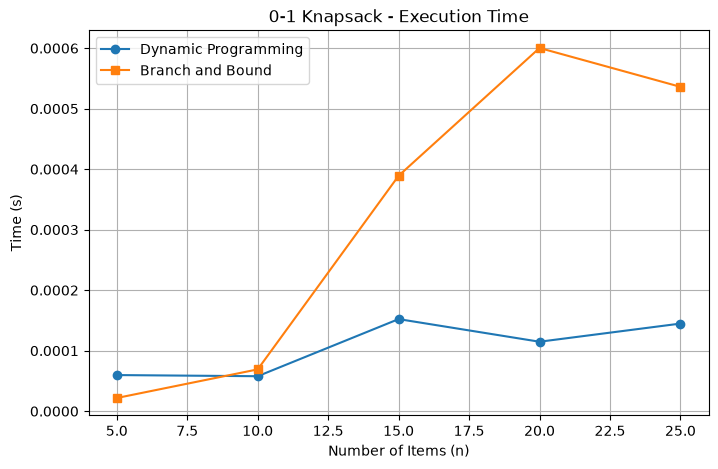

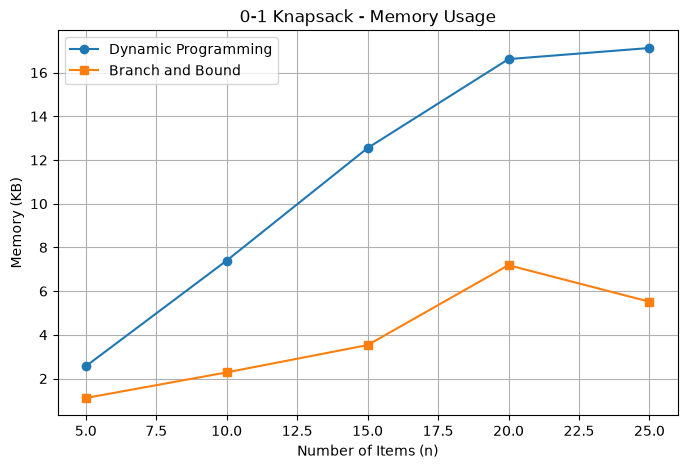

In [2]:
from time import perf_counter
import matplotlib.pyplot as plt
import statistics
import random
import tracemalloc


def measure_time(function, *args, repeats=5):
    times = []
    for _ in range(repeats):
        start = perf_counter()
        function(*args)
        times.append(perf_counter() - start)
    return statistics.median(times)


def measure_memory(function, *args, repeats=3):
    memory_values = []
    for _ in range(repeats):
        tracemalloc.start()
        function(*args)
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        memory_values.append(peak / 1024)
    return statistics.median(memory_values)


capacity = 50
random.seed(10)
sizes = [5, 10, 15, 20, 25]

dp_times, bb_times = [], []
dp_memory, bb_memory = [], []

for n in sizes:
    test_weights = [random.randint(1, 20) for _ in range(n)]
    test_profits = [random.randint(10, 100) for _ in range(n)]

    dp_times.append(measure_time(dp_knapsack, test_weights, test_profits, capacity))
    bb_times.append(measure_time(bb_knapsack, test_weights, test_profits, capacity))
    dp_memory.append(measure_memory(dp_knapsack, test_weights, test_profits, capacity))
    bb_memory.append(measure_memory(bb_knapsack, test_weights, test_profits, capacity))


print("Items\tDP Time (s)\tB&B Time (s)\tDP Mem (KB)\tB&B Mem (KB)")
for n, dt, bt, dm, bm in zip(sizes, dp_times, bb_times, dp_memory, bb_memory):
    print(f"{n}\t{dt:.8f}\t{bt:.8f}\t{dm:.3f}\t\t{bm:.3f}")


plt.figure(figsize=(8, 5))
plt.plot(sizes, dp_times, marker='o', label="Dynamic Programming")
plt.plot(sizes, bb_times, marker='s', label="Branch and Bound")
plt.xlabel("Number of Items (n)")
plt.ylabel("Time (s)")
plt.title("0-1 Knapsack - Execution Time")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(8, 5))
plt.plot(sizes, dp_memory, marker='o', label="Dynamic Programming")
plt.plot(sizes, bb_memory, marker='s', label="Branch and Bound")
plt.xlabel("Number of Items (n)")
plt.ylabel("Memory (KB)")
plt.title("0-1 Knapsack - Memory Usage")
plt.legend()
plt.grid(True)
plt.show()